# 0. Cadrage

**Contexte** : Les données nettoyées contiennent 4052 lignes (clients) et 7 colonnes (fonctionnalités) incluant un `Churn(Resiliation)`.

**Objectif** : prédire quels clients d’un opérateur télécom vont résilier leur abonnement, pour que l’entreprise puisse agir avant leur départ.

**Variables explicatives** :  6 variables

**Cible** : `« churn »`

**Evaluation** : Accent sur le `recall`

**Démarche** : Split stratifié, prétraitement dans un pipeline (sans fuite de données), comparaison de modèles en validation croisée, optimisation par `GridSearchCV`, évaluation finale sur le test, interprétation.

**Contrainte métier** : Rater un client qui va résilier coûte cher.

# 1. Librairies

In [1]:
import pandas as pd
from pathlib import Path
import matplotlib.pyplot as plt

In [2]:
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OrdinalEncoder, StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer

In [3]:
from sklearn.model_selection import (
    train_test_split, 
    cross_validate,
    StratifiedKFold,
    GridSearchCV
)

In [4]:
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier

In [5]:
from sklearn.metrics import (
    ConfusionMatrixDisplay,
    classification_report,
    precision_score,
    recall_score,
    f1_score
)

In [6]:
SEED = 42

In [7]:
BASE_DIR = Path.cwd().parent
DATA_DIR = BASE_DIR / "data"
CLEAN_DIR = DATA_DIR / "clean"
CLEAN_FILE = CLEAN_DIR / "churn_clean.parquet"

In [8]:
df = pd.read_parquet(CLEAN_FILE)
df.head()

,age,sexe,anciennete_mois,montant_mensuel_fcfa,nb_reclamations,type_contrat,churn
0,43.0,femme,53.0,18800.0,2,mensuel,0
1,24.0,femme,28.0,7200.0,0,annuel,0
2,63.0,homme,51.0,6600.0,2,mensuel,0
3,20.0,femme,13.0,16600.0,0,mensuel,0
4,52.0,femme,67.0,16000.0,3,mensuel,0


# 2. Separation X / y

In [9]:
X = df.drop('churn', axis=1)
y = df['churn']

X_train, X_test, y_train, y_test = train_test_split(X, y,
                                                   stratify = y,
                                                   test_size=0.2,
                                                   random_state=SEED)

print(f"Echantillon train : {len(X_train)} | Echantillon train : {len(X_test)}")

print("\nPourcentage train")
print(pd.Series(y_train).value_counts(normalize=True).round(3))

print("\nPourcentage test")
print(pd.Series(y_test).value_counts(normalize=True).round(3))

Echantillon train : 3241 | Echantillon train : 811

Pourcentage train
churn
0    0.791
1    0.209
Name: proportion, dtype: float64

Pourcentage test
churn
0    0.79
1    0.21
Name: proportion, dtype: float64


# 3. Preprocessor

In [10]:
df.dtypes

age                     float64
sexe                     object
anciennete_mois         float64
montant_mensuel_fcfa    float64
nb_reclamations           int64
type_contrat             object
churn                     int64
dtype: object

In [11]:
num_cols = df.select_dtypes("number").columns.drop('churn')
nom_cols = ['sexe']
ord_cols = ['type_contrat']

print(f"Colonnes numeriques : {num_cols}")
print(f"Colonnes nominales : {nom_cols}")
print(f"Colonnes ordinales : {ord_cols}")

Colonnes numeriques : Index(['age', 'anciennete_mois', 'montant_mensuel_fcfa', 'nb_reclamations'], dtype='object')
Colonnes nominales : ['sexe']
Colonnes ordinales : ['type_contrat']


In [18]:
num_pipe = Pipeline([
    ("imputer", SimpleImputer(strategy='median')),
    ("scaler", StandardScaler())
])

nom_pipe = Pipeline([
    ("imputer", SimpleImputer(strategy='most_frequent')),
    ("onehot", OneHotEncoder(drop="if_binary"))
])

order_type = ['mensuel', 'annuel', 'bisannuel']
ord_pipe = Pipeline([
    ("imputer", SimpleImputer(strategy='most_frequent')),
    ("ordinal", OrdinalEncoder(categories=[order_type]))
])

In [19]:
preprocessor = ColumnTransformer([
    ("num", num_pipe, num_cols),
    ("nom", nom_pipe, nom_cols),
    ("ord", ord_pipe, ord_cols)
],
     remainder='drop',
)
preprocessor

ColumnTransformer(transformers=[('num',
                                 Pipeline(steps=[('imputer',
                                                  SimpleImputer(strategy='median')),
                                                 ('scaler', StandardScaler())]),
                                 Index(['age', 'anciennete_mois', 'montant_mensuel_fcfa', 'nb_reclamations'], dtype='object')),
                                ('nom',
                                 Pipeline(steps=[('imputer',
                                                  SimpleImputer(strategy='most_frequent')),
                                                 ('onehot',
                                                  OneHotEncoder(drop='if_binary'))]),
                                 ['sexe']),
                                ('ord',
                                 Pipeline(steps=[('imputer',
                                                  SimpleImputer(strategy='most_frequent')),
                                                 ('ordinal',
                                                  OrdinalEncoder(categories=[['mensuel',
                                                                              'annuel',
                                                                              'bisannuel']]))]),
                                 ['type_contrat'])])

# 4. Premiers scores

#### Models

In [20]:
modeles = {
    "LogReg" : LogisticRegression(),
    "RDF" : RandomForestClassifier()
}

#### Metrics

In [21]:
SCORING = ["precision", "recall", "f1"]

#### Cross Validate

In [22]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)

In [23]:
resultats = []

for nom, modele in modeles.items():
    pipe = Pipeline([("prep", preprocessor), ("model", modele)])
    
    scores = cross_validate(
        pipe, X, y,
        cv=cv,
        scoring=SCORING,
        n_jobs=-1
    )
    
    resultats.append({
        "nom" : nom,
        "precision" : scores['test_precision'].mean().round(3),
        "recall" : scores["test_recall"].mean().round(3),
        "f1" : scores["test_f1"].mean().round(3),
        "fit" : scores["fit_time"].mean().round(3)
    })

print(pd.DataFrame(resultats).sort_values(by="recall", ascending=False))

      nom  precision  recall     f1    fit
0  LogReg      0.738   0.577  0.646  0.098
1     RDF      0.709   0.546  0.616  0.762


#### Matrice de confusion

In [24]:
predictions = []

for modele in modeles.values():
    pipe = Pipeline([("prep", preprocessor), ("model", modele)])
    pipe.fit(X_train, y_train)
    y_pred = (pipe.predict(X_test))
    predictions.append(y_pred)

<Figure size 1200x600 with 0 Axes>

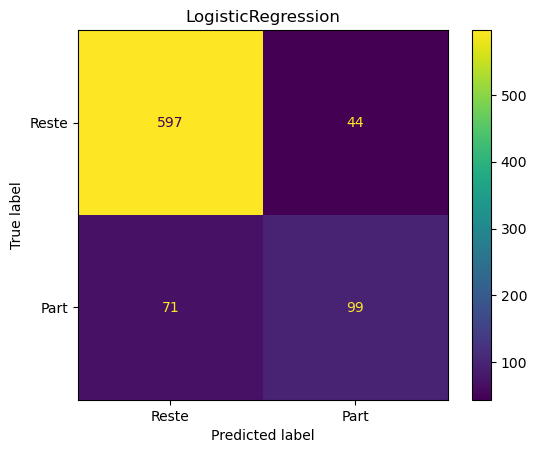

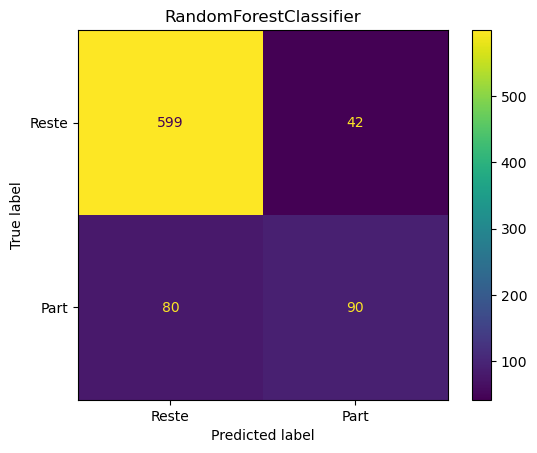

In [25]:
plt.figure(figsize=(12,6))
noms = ["LogisticRegression", "RandomForestClassifier"]

for i, nom in enumerate(noms) :
    #plt.subplot(1,2,i+1)
    ConfusionMatrixDisplay.from_predictions(y_test, predictions[i], display_labels=["Reste", "Part"])
    plt.title(f"{nom}")
    plt.show()

**Choix** : **`LogisticRegression()`**

**Justifiaction** :
 - Meilleurs scores que le RandomForestClassifier avec un fit_time 7 fois pus rapide

# 6. Final model

In [26]:
pipe_logreg = Pipeline([("prep", preprocessor), ("model", LogisticRegression())])

In [27]:
LogisticRegression().get_params()

{'C': 1.0,
 'class_weight': None,
 'dual': False,
 'fit_intercept': True,
 'intercept_scaling': 1,
 'l1_ratio': None,
 'max_iter': 100,
 'multi_class': 'deprecated',
 'n_jobs': None,
 'penalty': 'l2',
 'random_state': None,
 'solver': 'lbfgs',
 'tol': 0.0001,
 'verbose': 0,
 'warm_start': False}

#### Hyperparametres

In [28]:
param_grid = {
    "model__max_iter" : [100, 500, 1000, 1500],
    "model__class_weight" : [None, 'balanced'],
    "model__C" : [0.01, 0.1, 1, 10, 100]
}

#### Metrics

In [29]:
SCORING = {
    "precision" : "precision",
    "recall" : "recall",
    "f1" : "f1"
}

### Recherche

In [30]:
grid = GridSearchCV(estimator=pipe_logreg,
                   param_grid=param_grid,
                   cv=cv,
                   scoring=SCORING,
                   n_jobs=-1,
                   refit='recall')

In [31]:
grid.fit(X_train, y_train)

GridSearchCV(cv=StratifiedKFold(n_splits=5, random_state=42, shuffle=True),
             estimator=Pipeline(steps=[('prep',
                                        ColumnTransformer(transformers=[('num',
                                                                         Pipeline(steps=[('imputer',
                                                                                          SimpleImputer(strategy='median')),
                                                                                         ('scaler',
                                                                                          StandardScaler())]),
                                                                         Index(['age', 'anciennete_mois', 'montant_mensuel_fcfa', 'nb_reclamations'], dtype='object')),
                                                                        ('nom',
                                                                         Pipeline(steps=[...
                                                                                          SimpleImputer(strategy='most_frequent')),
                                                                                         ('ordinal',
                                                                                          OrdinalEncoder(categories=[['mensuel',
                                                                                                                      'annuel',
                                                                                                                      'bisannuel']]))]),
                                                                         ['type_contrat'])])),
                                       ('model', LogisticRegression())]),
             n_jobs=-1,
             param_grid={'model__C': [0.01, 0.1, 1, 10, 100],
                         'model__class_weight': [None, 'balanced'],
                         'model__max_iter': [100, 500, 1000, 1500]},
             refit='recall',
             scoring={'f1': 'f1', 'precision': 'precision', 'recall': 'recall'})

In [32]:
print(f"Meilleurs parametres : {grid.best_params_}")
print(f"Meilleur score : {grid.best_score_}")

Meilleurs parametres : {'model__C': 0.01, 'model__class_weight': 'balanced', 'model__max_iter': 100}
Meilleur score : 0.8465686274509803


#### Sauvegarde du meilleur model

In [33]:
model = grid.best_estimator_

# 7. Evaluation finale

In [34]:
y_pred = model.predict(X_test)

print(classification_report(y_test, y_pred, target_names=['Reste', 'Part']))

              precision    recall  f1-score   support

       Reste       0.95      0.79      0.86       641
        Part       0.52      0.85      0.64       170

    accuracy                           0.80       811
   macro avg       0.73      0.82      0.75       811
weighted avg       0.86      0.80      0.82       811



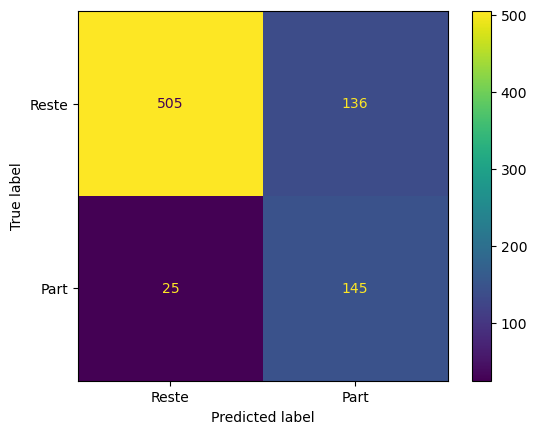

In [35]:
ConfusionMatrixDisplay.from_predictions(y_test, y_pred, display_labels=['Reste', 'Part'])
plt.show()